In [1]:
from pathlib import Path
import pandas as pd

# Find the project folder
project_root = Path.cwd()

if not (project_root / "input").exists():
    project_root = project_root.parent

# Find every CSV file inside the input folder
csv_files = sorted((project_root / "input").rglob("*.csv"))

print(f"Found {len(csv_files)} CSV files")

# Record the size of each table
audit_results = []

for file in csv_files:
    table = pd.read_csv(file)

    audit_results.append({
        "file": file.name,
        "rows": len(table),
        "columns": len(table.columns),
        "duplicate_rows": int(table.duplicated().sum())
    })

audit_table = pd.DataFrame(audit_results)
audit_table

Found 11 CSV files


,file,rows,columns,duplicate_rows
0,olist_customers_dataset.csv,99441,5,0
1,olist_geolocation_dataset.csv,1000163,5,261831
2,olist_order_items_dataset.csv,112650,7,0
3,olist_order_payments_dataset.csv,103886,5,0
4,olist_order_reviews_dataset.csv,99224,7,0
5,olist_orders_dataset.csv,99441,8,0
6,olist_products_dataset.csv,32951,9,0
7,olist_sellers_dataset.csv,3095,4,0
8,product_category_name_translation.csv,71,2,0
9,olist_closed_deals_dataset.csv,842,14,0


In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os

print('### Marketing Funnel by Olist ###')
for idx, file in enumerate(os.listdir('../input/marketing-funnel-olist')):
    print(idx, '-', file)
print('\n---------------------------------------------\n')

print('### Brazilian E-Commerce Public Dataset by Olist ###')
for idx, file in enumerate(os.listdir('../input/brazilian-ecommerce')):
    print(idx, '-', file)

### Marketing Funnel by Olist ###
0 - .complete
1 - olist_marketing_qualified_leads_dataset.csv
2 - olist_closed_deals_dataset.csv

---------------------------------------------

### Brazilian E-Commerce Public Dataset by Olist ###
0 - olist_orders_dataset.csv
1 - olist_sellers_dataset.csv
2 - olist_products_dataset.csv
3 - olist_geolocation_dataset.csv
4 - olist_order_items_dataset.csv
5 - .complete
6 - olist_order_payments_dataset.csv
7 - product_category_name_translation.csv
8 - olist_customers_dataset.csv
9 - olist_order_reviews_dataset.csv


## Data Schema

This dataset may be easily linked to the Brazilian Ecommerce Public Dataset, just follow the data schema presented bellow:
![](https://i.imgur.com/Jory0O3.png)

In [3]:
# leads dataset
mql = pd.read_csv('../input/marketing-funnel-olist/olist_marketing_qualified_leads_dataset.csv')
mql.head(10)

,mql_id,first_contact_date,landing_page_id,origin
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search
5,28bdfd5f057764b54c38770f95c69f2f,2018-01-14,22c29808c4f815213303f8933030604c,organic_search
6,126a0d10becbaafcb2e72ce6848cf32c,2018-05-15,6a110e795dd487f1cf8d7583671987af,email
7,f76136f54d14a3345951f25b7932366b,2018-05-24,d51b0d02f063ba1d053db6d97226eec3,email
8,2f838cade4a6012a6cb1016d1d8d95ed,2017-11-10,aeac92c0f5ae22a04ed3b746cce3a1b6,organic_search
9,7281942387a1a0c3f72a50a8b0bb0920,2017-12-25,88740e65d5d6b056e0cda098e1ea6313,social


In [4]:
# closed deals dataset
cd = pd.read_csv('../input/marketing-funnel-olist/olist_closed_deals_dataset.csv')
cd.head(10)

,mql_id,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,5420aad7fec3549a85876ba1c529bd84,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0
1,a555fb36b9368110ede0f043dfc3b9a0,bbb7d7893a450660432ea6652310ebb7,09285259593c61296eef10c734121d5b,d3d1e91a157ea7f90548eef82f1955e3,2018-05-08 20:17:59,car_accessories,industry,eagle,NaN,NaN,NaN,reseller,NaN,0.0
2,327174d3648a2d047e8940d7d15204ca,612170e34b97004b3ba37eae81836b4c,b90f87164b5f8c2cfa5c8572834dbe3f,6565aa9ce3178a5caf6171827af3a9ba,2018-06-05 17:27:23,home_appliances,online_big,cat,NaN,NaN,NaN,reseller,NaN,0.0
3,f5fee8f7da74f4887f5bcae2bafb6dd6,21e1781e36faf92725dde4730a88ca0f,56bf83c4bb35763a51c2baab501b4c67,d3d1e91a157ea7f90548eef82f1955e3,2018-01-17 13:51:03,food_drink,online_small,NaN,NaN,NaN,NaN,reseller,NaN,0.0
4,ffe640179b554e295c167a2f6be528e0,ed8cb7b190ceb6067227478e48cf8dde,4b339f9567d060bcea4f5136b9f5949e,d3d1e91a157ea7f90548eef82f1955e3,2018-07-03 20:17:45,home_appliances,industry,wolf,NaN,NaN,NaN,manufacturer,NaN,0.0
5,b94fba7670eeb44dce2a0d8eb790e9f5,1c742ac33582852aaf3bcfbf5893abcf,fdb16d3cbbeb5798f2f66c4096be026d,495d4e95a8cf8bbf8b432b612a2aa328,2018-02-07 18:04:05,health_beauty,online_medium,NaN,NaN,NaN,NaN,manufacturer,NaN,0.0
6,c3e30ed7ac989117c7e1e719b4ac128f,92d7568ad0c5c76fd7d341b2d46f24d6,4b339f9567d060bcea4f5136b9f5949e,85fc447d336637ba1df43e793199fbc8,2018-04-16 18:18:22,computers,online_medium,wolf,NaN,NaN,NaN,reseller,NaN,0.0
7,b02c89251106e1fdd9d92744be9f94f2,44ed138eca6214d572ce1d813fb0049b,34d40cdaf94010a1d05b0d6212f9e909,4ef15afb4b2723d8f3d81e51ec7afefe,2018-04-17 17:01:57,health_beauty,offline,cat,NaN,NaN,NaN,manufacturer,NaN,0.0
8,a90a37898cc5f2718385a2fb981caaff,0b28859cd04d23edefee9c591fb03cd8,f42a2bd194f7802ab052a815c8de65b7,6565aa9ce3178a5caf6171827af3a9ba,2018-05-14 18:37:15,household_utilities,offline,eagle,NaN,NaN,NaN,reseller,NaN,0.0
9,0173e8d8b1d94a355b440fb67388f532,87d73636a3acf123e842bb890a4db036,9d12ef1a7eca3ec58c545c678af7869c,9e4d1098a3b0f5da39b0bc48f9876645,2018-04-24 03:00:00,household_utilities,online_medium,eagle,NaN,NaN,NaN,manufacturer,NaN,0.0


In [5]:
# marketing funnel dataset (NaNs are leads that did not close a deal)
mf = mql.merge(cd, on='mql_id', how='left')
mf.head(10)

,mql_id,first_contact_date,landing_page_id,origin,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0
5,28bdfd5f057764b54c38770f95c69f2f,2018-01-14,22c29808c4f815213303f8933030604c,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,126a0d10becbaafcb2e72ce6848cf32c,2018-05-15,6a110e795dd487f1cf8d7583671987af,email,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,f76136f54d14a3345951f25b7932366b,2018-05-24,d51b0d02f063ba1d053db6d97226eec3,email,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2f838cade4a6012a6cb1016d1d8d95ed,2017-11-10,aeac92c0f5ae22a04ed3b746cce3a1b6,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,7281942387a1a0c3f72a50a8b0bb0920,2017-12-25,88740e65d5d6b056e0cda098e1ea6313,social,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# sellers dataset
sellers = pd.read_csv('../input/brazilian-ecommerce/olist_sellers_dataset.csv')
sellers.head(10)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
5,c240c4061717ac1806ae6ee72be3533b,20920,rio de janeiro,RJ
6,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,PE
7,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,SP
8,768a86e36ad6aae3d03ee3c6433d61df,1529,sao paulo,SP
9,ccc4bbb5f32a6ab2b7066a4130f114e3,80310,curitiba,PR


In [7]:
# marketing funnel merged with sellers (this way you get seller location)
mf_sellers = mf.merge(sellers, on='seller_id', how='left')
mf_sellers.head(10)

,mql_id,first_contact_date,landing_page_id,origin,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue,seller_zip_code_prefix,seller_city,seller_state
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0,30421.0,belo horizonte,MG
5,28bdfd5f057764b54c38770f95c69f2f,2018-01-14,22c29808c4f815213303f8933030604c,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,126a0d10becbaafcb2e72ce6848cf32c,2018-05-15,6a110e795dd487f1cf8d7583671987af,email,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,f76136f54d14a3345951f25b7932366b,2018-05-24,d51b0d02f063ba1d053db6d97226eec3,email,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2f838cade4a6012a6cb1016d1d8d95ed,2017-11-10,aeac92c0f5ae22a04ed3b746cce3a1b6,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,7281942387a1a0c3f72a50a8b0bb0920,2017-12-25,88740e65d5d6b056e0cda098e1ea6313,social,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# order items dataset
items = pd.read_csv('../input/brazilian-ecommerce/olist_order_items_dataset.csv')
items.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40


In [9]:
# marketing funnel merged with items (this way you get products sold by sellers)
mf_items = mf.merge(items, on='seller_id', how='left')
mf_items.head(10)

,mql_id,first_contact_date,landing_page_id,origin,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,...,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue,order_id,order_item_id,product_id,shipping_limit_date,price,freight_value
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,...,NaN,reseller,NaN,0.0,1efcc6ba75b519535a510c53153a9256,1.0,e94df75b2e9a8b056be0c144a731f55c,2018-06-26 22:20:21,94.2,18.76
5,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,...,NaN,reseller,NaN,0.0,d8d281c1a1398a1e835fdc4adfb81e2a,1.0,9e0873e9ac04b12f282b81af5daebd2e,2018-07-30 09:31:49,664.0,38.41
6,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,...,NaN,reseller,NaN,0.0,e5858127da61f07285827883e605254b,1.0,9bb2d066e4b33b624cbdfec7d50b3dcb,2018-06-27 16:00:04,99.8,15.00
7,28bdfd5f057764b54c38770f95c69f2f,2018-01-14,22c29808c4f815213303f8933030604c,organic_search,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,126a0d10becbaafcb2e72ce6848cf32c,2018-05-15,6a110e795dd487f1cf8d7583671987af,email,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,f76136f54d14a3345951f25b7932366b,2018-05-24,d51b0d02f063ba1d053db6d97226eec3,email,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We hope you enjoy this new dataset and its interaction with the Brazilian E-commerce Public Dataset!

In [10]:
from pathlib import Path
import pandas as pd

# Find the project folder
project_root = Path.cwd()

if not (project_root / "input").exists():
    project_root = project_root.parent

# Find every CSV file inside the input folder
csv_files = sorted((project_root / "input").rglob("*.csv"))

print(f"Found {len(csv_files)} CSV files")

# Record the size of each table
audit_results = []

for file in csv_files:
    table = pd.read_csv(file)

    audit_results.append({
        "file": file.name,
        "rows": len(table),
        "columns": len(table.columns),
        "duplicate_rows": int(table.duplicated().sum())
    })

audit_table = pd.DataFrame(audit_results)
audit_table

Found 11 CSV files


,file,rows,columns,duplicate_rows
0,olist_customers_dataset.csv,99441,5,0
1,olist_geolocation_dataset.csv,1000163,5,261831
2,olist_order_items_dataset.csv,112650,7,0
3,olist_order_payments_dataset.csv,103886,5,0
4,olist_order_reviews_dataset.csv,99224,7,0
5,olist_orders_dataset.csv,99441,8,0
6,olist_products_dataset.csv,32951,9,0
7,olist_sellers_dataset.csv,3095,4,0
8,product_category_name_translation.csv,71,2,0
9,olist_closed_deals_dataset.csv,842,14,0


## Lesson 2 — Table grain and key checks

**Grain** means what one row represents. Before joining tables, we must know each table's grain and test its expected key.

- A **primary key** identifies one row uniquely.
- A **foreign key** connects a row to another table.
- A one-to-many relationship means one record in one table can match several records in another.

The next cell loads the core fulfillment tables and checks whether their expected keys are unique.

In [11]:
from pathlib import Path
import pandas as pd

# Locate the input folder even when the notebook is opened from /notebooks.
project_root = Path.cwd()
if not (project_root / "input").exists():
    project_root = project_root.parent


def load_csv(file_name: str) -> pd.DataFrame:
    """Find and load one CSV file from the project's input folders."""
    file_path = next((project_root / "input").rglob(file_name))
    return pd.read_csv(file_path)


# Load only the core tables needed for fulfillment analysis.
orders = load_csv("olist_orders_dataset.csv")
customers = load_csv("olist_customers_dataset.csv")
order_items = load_csv("olist_order_items_dataset.csv")
payments = load_csv("olist_order_payments_dataset.csv")
sellers = load_csv("olist_sellers_dataset.csv")


def check_grain(
    table: pd.DataFrame,
    table_name: str,
    key_columns: list[str],
    expected_grain: str,
) -> dict:
    """Check whether the expected key uniquely identifies every row."""
    duplicate_keys = int(table.duplicated(subset=key_columns).sum())
    return {
        "table": table_name,
        "expected_grain": expected_grain,
        "rows": len(table),
        "unique_keys": len(table.drop_duplicates(subset=key_columns)),
        "duplicate_keys": duplicate_keys,
        "key_test": "PASS" if duplicate_keys == 0 else "REVIEW",
    }


# A key can contain one column or a combination of columns.
grain_results = pd.DataFrame([
    check_grain(orders, "orders", ["order_id"], "one row per order"),
    check_grain(customers, "customers", ["customer_id"], "one row per order-customer record"),
    check_grain(sellers, "sellers", ["seller_id"], "one row per seller"),
    check_grain(
        order_items,
        "order_items",
        ["order_id", "order_item_id"],
        "one row per item position in an order",
    ),
    check_grain(
        payments,
        "payments",
        ["order_id", "payment_sequential"],
        "one row per payment attempt in an order",
    ),
])

# Compare row counts with distinct order counts to reveal one-to-many tables.
order_relationships = pd.DataFrame([
    {
        "table": "orders",
        "rows": len(orders),
        "distinct_order_ids": orders["order_id"].nunique(),
    },
    {
        "table": "order_items",
        "rows": len(order_items),
        "distinct_order_ids": order_items["order_id"].nunique(),
    },
    {
        "table": "payments",
        "rows": len(payments),
        "distinct_order_ids": payments["order_id"].nunique(),
    },
])

display(grain_results)
display(order_relationships)

,table,expected_grain,rows,unique_keys,duplicate_keys,key_test
0,orders,one row per order,99441,99441,0,PASS
1,customers,one row per order-customer record,99441,99441,0,PASS
2,sellers,one row per seller,3095,3095,0,PASS
3,order_items,one row per item position in an order,112650,112650,0,PASS
4,payments,one row per payment attempt in an order,103886,103886,0,PASS


,table,rows,distinct_order_ids
0,orders,99441,99441
1,order_items,112650,98666
2,payments,103886,99440


### What we learned

All five expected keys passed the uniqueness test.

- **Orders:** 99,441 rows = 99,441 distinct orders. This is our safe order-count table.
- **Order items:** 112,650 rows represent 98,666 distinct orders. One order may contain several item rows.
- **Payments:** 103,886 rows represent 99,440 distinct orders. One order may have several payment rows.

**Rule for this project:** calculate delivery KPIs from the order-level table. Use item rows for product, seller, price, and freight analysis only after controlling the grain.

## Lesson 3 — Build the order-level delivery table

This table must keep exactly **one row per order**.

We will:

1. Join orders to customers using customer_id.
2. Require a one-to-one match so the join cannot multiply orders.
3. Convert text timestamps into real Python dates.
4. Define which delivered orders are eligible for delivery KPIs.
5. Calculate delivery days, late days, and the on-time flag.

**Eligibility rule:** order status is delivered and the purchase, actual-delivery, and estimated-delivery timestamps are all present.

In [12]:
import pandas as pd

# Join customer location onto orders without changing the order grain.
customer_columns = [
    "customer_id",
    "customer_unique_id",
    "customer_zip_code_prefix",
    "customer_city",
    "customer_state",
]

order_level = orders.merge(
    customers[customer_columns],
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# Convert timestamp text into datetime values that Python can subtract.
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in date_columns:
    order_level[column] = pd.to_datetime(order_level[column], errors="coerce")

# Only these orders belong in the delivery KPI denominator.
is_delivered = order_level["order_status"].eq("delivered")
has_required_dates = order_level[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
].notna().all(axis=1)

order_level["eligible_delivery_kpi"] = is_delivered & has_required_dates
eligible_mask = order_level["eligible_delivery_kpi"]

# Calculate delivery performance only for eligible orders.
order_level["delivery_days"] = (
    (
        order_level["order_delivered_customer_date"]
        - order_level["order_purchase_timestamp"]
    )
    / pd.Timedelta(days=1)
).where(eligible_mask)

signed_days_vs_estimate = (
    (
        order_level["order_delivered_customer_date"]
        - order_level["order_estimated_delivery_date"]
    )
    / pd.Timedelta(days=1)
).where(eligible_mask)

order_level["late_days"] = signed_days_vs_estimate.clip(lower=0)

order_level["on_time_flag"] = pd.Series(
    pd.NA,
    index=order_level.index,
    dtype="boolean",
)
order_level.loc[eligible_mask, "on_time_flag"] = (
    order_level.loc[eligible_mask, "order_delivered_customer_date"]
    <= order_level.loc[eligible_mask, "order_estimated_delivery_date"]
)

# Validate that the join and calculations preserved trustworthy order grain.
unmatched_customers = int(order_level["_merge"].ne("both").sum())
negative_delivery_days = int(order_level["delivery_days"].lt(0).sum())

quality_checks = pd.DataFrame([
    {
        "check": "Order count unchanged after customer join",
        "result": len(order_level) == len(orders),
        "observed": len(order_level),
    },
    {
        "check": "order_id remains unique",
        "result": order_level["order_id"].is_unique,
        "observed": order_level["order_id"].nunique(),
    },
    {
        "check": "Every order matched a customer",
        "result": unmatched_customers == 0,
        "observed": unmatched_customers,
    },
    {
        "check": "No negative delivery durations",
        "result": negative_delivery_days == 0,
        "observed": negative_delivery_days,
    },
])

eligible_orders = order_level.loc[eligible_mask]
delivered_order_count = int(is_delivered.sum())
excluded_delivered_orders = delivered_order_count - len(eligible_orders)
late_orders = eligible_orders.loc[eligible_orders["late_days"].gt(0)]

kpi_summary = pd.DataFrame([
    {"metric": "Total orders", "value": len(order_level)},
    {"metric": "Delivered orders", "value": delivered_order_count},
    {"metric": "Eligible delivered orders", "value": len(eligible_orders)},
    {"metric": "Delivered orders excluded for missing dates", "value": excluded_delivered_orders},
    {
        "metric": "On-time delivery rate (%)",
        "value": round(float(eligible_orders["on_time_flag"].mean() * 100), 2),
    },
    {
        "metric": "Median delivery days",
        "value": round(float(eligible_orders["delivery_days"].median()), 2),
    },
    {
        "metric": "P90 delivery days",
        "value": round(float(eligible_orders["delivery_days"].quantile(0.90)), 2),
    },
    {
        "metric": "Mean late days among late orders",
        "value": round(float(late_orders["late_days"].mean()), 2),
    },
])

# Remove the temporary merge diagnostic after the checks are complete.
order_level = order_level.drop(columns="_merge")

display(quality_checks)
display(kpi_summary)

,check,result,observed
0,Order count unchanged after customer join,True,99441
1,order_id remains unique,True,99441
2,Every order matched a customer,True,0
3,No negative delivery durations,True,0


,metric,value
0,Total orders,99441.00
1,Delivered orders,96478.00
2,Eligible delivered orders,96470.00
3,Delivered orders excluded for missing dates,8.00
4,On-time delivery rate (%),91.89
5,Median delivery days,10.22
6,P90 delivery days,23.10
7,Mean late days among late orders,9.55


### Lesson 3 result

The customer join preserved the order grain and all four quality checks passed.

- **Total orders:** 99,441
- **Delivered orders:** 96,478
- **Eligible delivered orders:** 96,470
- **Excluded delivered orders:** 8, because required timestamps were missing
- **On-time delivery rate:** 91.89%
- **Median delivery time:** 10.22 days
- **P90 delivery time:** 23.10 days
- **Mean delay among late orders:** 9.55 days

**Interpretation:** half of eligible orders arrived within 10.22 days. Ninety percent arrived within 23.10 days. The eight excluded delivered orders remain in the order table but are not counted in the delivery KPI denominator.

## Lesson 4 — Build the seller-order corridor table

The new grain is one row per unique **order_id + seller_id** pair.

We first aggregate item rows because one seller may supply several items in the same order. Then we attach the seller state and the order-level customer and delivery fields.

A **corridor** is **seller_state → customer_state**.

**Important limitation:** this is a seller-order fulfillment proxy, not a confirmed physical parcel. An order with multiple sellers contributes one row for each participating seller.

In [13]:
# Collapse item rows to one row per seller participating in an order.
seller_order_base = (
    order_items.groupby(["order_id", "seller_id"], as_index=False)
    .agg(
        item_rows=("order_item_id", "count"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
    )
)

seller_order_key_is_unique = not seller_order_base.duplicated(
    subset=["order_id", "seller_id"]
).any()

seller_order = seller_order_base.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id",
    how="left",
    validate="many_to_one",
    indicator="_seller_join",
)

order_context_columns = [
    "order_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "customer_city",
    "customer_state",
    "eligible_delivery_kpi",
    "delivery_days",
    "late_days",
    "on_time_flag",
]

seller_order = seller_order.merge(
    order_level[order_context_columns],
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator="_order_join",
)

seller_order["same_state"] = seller_order["seller_state"].eq(
    seller_order["customer_state"]
)
seller_order["corridor"] = (
    seller_order["seller_state"] + " → " + seller_order["customer_state"]
)
seller_order["eligible_corridor_kpi"] = (
    seller_order["eligible_delivery_kpi"].fillna(False)
    & seller_order["seller_state"].notna()
    & seller_order["customer_state"].notna()
)

missing_seller_matches = int(seller_order["_seller_join"].ne("both").sum())
missing_order_matches = int(seller_order["_order_join"].ne("both").sum())
seller_count_per_order = seller_order_base.groupby("order_id")["seller_id"].nunique()
multi_seller_orders = int(seller_count_per_order.gt(1).sum())

quality_checks = pd.DataFrame([
    {
        "check": "seller-order key is unique",
        "result": seller_order_key_is_unique,
        "observed": int(
            seller_order_base.duplicated(["order_id", "seller_id"]).sum()
        ),
    },
    {
        "check": "Every seller-order matched a seller",
        "result": missing_seller_matches == 0,
        "observed": missing_seller_matches,
    },
    {
        "check": "Every seller-order matched an order",
        "result": missing_order_matches == 0,
        "observed": missing_order_matches,
    },
    {
        "check": "Merchandise total preserved",
        "result": abs(
            seller_order_base["merchandise_value"].sum()
            - order_items["price"].sum()
        ) < 0.01,
        "observed": round(
            seller_order_base["merchandise_value"].sum()
            - order_items["price"].sum(),
            2,
        ),
    },
    {
        "check": "Freight total preserved",
        "result": abs(
            seller_order_base["freight_value"].sum()
            - order_items["freight_value"].sum()
        ) < 0.01,
        "observed": round(
            seller_order_base["freight_value"].sum()
            - order_items["freight_value"].sum(),
            2,
        ),
    },
])

eligible_seller_orders = seller_order.loc[
    seller_order["eligible_corridor_kpi"]
]
same_state_count = int(eligible_seller_orders["same_state"].sum())
cross_state_count = int((~eligible_seller_orders["same_state"]).sum())

seller_order_summary = pd.DataFrame([
    {"metric": "Input item rows", "value": len(order_items)},
    {"metric": "Seller-order rows", "value": len(seller_order)},
    {
        "metric": "Distinct orders represented",
        "value": seller_order["order_id"].nunique(),
    },
    {"metric": "Orders with multiple sellers", "value": multi_seller_orders},
    {
        "metric": "Eligible seller-orders",
        "value": len(eligible_seller_orders),
    },
    {
        "metric": "Same-state eligible seller-orders",
        "value": same_state_count,
    },
    {
        "metric": "Cross-state eligible seller-orders",
        "value": cross_state_count,
    },
    {
        "metric": "Cross-state share (%)",
        "value": round(
            cross_state_count / len(eligible_seller_orders) * 100,
            2,
        ),
    },
])

seller_order = seller_order.drop(columns=["_seller_join", "_order_join"])

display(quality_checks)
display(seller_order_summary)

,check,result,observed
0,seller-order key is unique,True,0.0
1,Every seller-order matched a seller,True,0.0
2,Every seller-order matched an order,True,0.0
3,Merchandise total preserved,True,-0.0
4,Freight total preserved,True,-0.0


,metric,value
0,Input item rows,112650.00
1,Seller-order rows,100010.00
2,Distinct orders represented,98666.00
3,Orders with multiple sellers,1278.00
4,Eligible seller-orders,97811.00
5,Same-state eligible seller-orders,35181.00
6,Cross-state eligible seller-orders,62630.00
7,Cross-state share (%),64.03


### Lesson 4 result

All five quality checks passed: the seller-order key is unique, all rows matched both source tables, and merchandise and freight totals were preserved.

- **Input item rows:** 112,650
- **Seller-order rows:** 100,010
- **Distinct orders represented:** 98,666
- **Orders with multiple sellers:** 1,278
- **Eligible seller-orders:** 97,811
- **Same-state eligible seller-orders:** 35,181
- **Cross-state eligible seller-orders:** 62,630
- **Cross-state share:** 64.03%

**Interpretation:** repeated items from the same seller in the same order no longer inflate corridor volume. The 100,010 seller-order rows are still greater than the 98,666 distinct orders because multi-seller orders contribute once for each participating seller.

**Methodology warning:** 64.03% is the share of eligible seller-order pairs that cross a state boundary. It is not the percentage of unique customer orders or confirmed physical parcels. The delivery timestamp belongs to the whole order and is used here only as a seller-order fulfillment proxy.

## Lesson 5 — Rank state corridors with a minimum-volume rule

A corridor is now one aggregated row for a **seller_state → customer_state** pair.

For each corridor we will measure seller-order volume, distinct orders, on-time and late-delivery rates, median and P90 delivery days, average late days, merchandise value, and freight value.

### Why use a minimum volume?

A tiny corridor can show an extreme rate by chance. We will compare minimums of **50, 100, and 200 eligible seller-orders** and measure both how many corridors remain and what share of eligible seller-orders they cover.

We will rank only after selecting a threshold that keeps useful coverage while reducing small-sample noise.

In [14]:
# Keep only seller-orders that meet the documented corridor KPI rule.
eligible_corridor_rows = seller_order.loc[
    seller_order["eligible_corridor_kpi"]
].copy()
eligible_corridor_rows["is_late"] = ~eligible_corridor_rows[
    "on_time_flag"
].astype(bool)

# Aggregate to one row per seller-state to customer-state corridor.
corridor_metrics = (
    eligible_corridor_rows.groupby(
        ["seller_state", "customer_state", "corridor", "same_state"],
        as_index=False,
    )
    .agg(
        seller_orders=("order_id", "size"),
        distinct_orders=("order_id", "nunique"),
        distinct_sellers=("seller_id", "nunique"),
        on_time_rate_pct=("on_time_flag", lambda values: values.mean() * 100),
        late_rate_pct=("is_late", lambda values: values.mean() * 100),
        median_delivery_days=("delivery_days", "median"),
        p90_delivery_days=("delivery_days", lambda values: values.quantile(0.90)),
        average_late_days=("late_days", "mean"),
        merchandise_value=("merchandise_value", "sum"),
        freight_value=("freight_value", "sum"),
    )
)

corridor_metrics["route_type"] = corridor_metrics["same_state"].map(
    {True: "Same-state", False: "Cross-state"}
)

round_columns = [
    "on_time_rate_pct",
    "late_rate_pct",
    "median_delivery_days",
    "p90_delivery_days",
    "average_late_days",
    "merchandise_value",
    "freight_value",
]
corridor_metrics[round_columns] = corridor_metrics[round_columns].round(2)

# Compare possible minimum-volume rules before selecting one.
threshold_rows = []
total_eligible_seller_orders = len(eligible_corridor_rows)
for minimum_seller_orders in [50, 100, 200]:
    qualified = corridor_metrics.loc[
        corridor_metrics["seller_orders"] >= minimum_seller_orders
    ]
    covered_seller_orders = int(qualified["seller_orders"].sum())
    threshold_rows.append(
        {
            "minimum_seller_orders": minimum_seller_orders,
            "corridors_retained": len(qualified),
            "seller_orders_covered": covered_seller_orders,
            "coverage_pct": round(
                covered_seller_orders / total_eligible_seller_orders * 100,
                2,
            ),
        }
    )

threshold_profile = pd.DataFrame(threshold_rows)

corridor_quality_checks = pd.DataFrame([
    {
        "check": "All eligible seller-orders were aggregated",
        "result": int(corridor_metrics["seller_orders"].sum())
        == total_eligible_seller_orders,
        "observed": int(corridor_metrics["seller_orders"].sum()),
    },
    {
        "check": "Each state corridor is unique",
        "result": not corridor_metrics.duplicated(
            ["seller_state", "customer_state"]
        ).any(),
        "observed": int(
            corridor_metrics.duplicated(
                ["seller_state", "customer_state"]
            ).sum()
        ),
    },
    {
        "check": "No eligible corridor has a missing state",
        "result": not corridor_metrics[
            ["seller_state", "customer_state"]
        ].isna().any().any(),
        "observed": int(
            corridor_metrics[
                ["seller_state", "customer_state"]
            ].isna().sum().sum()
        ),
    },
    {
        "check": "On-time and late rates reconcile to 100%",
        "result": (
            corridor_metrics["on_time_rate_pct"]
            + corridor_metrics["late_rate_pct"]
            - 100
        ).abs().le(0.02).all(),
        "observed": round(
            (
                corridor_metrics["on_time_rate_pct"]
                + corridor_metrics["late_rate_pct"]
                - 100
            ).abs().max(),
            2,
        ),
    },
])

display(corridor_quality_checks)
display(threshold_profile)
print(f"Total corridors before a threshold: {len(corridor_metrics):,}")

,check,result,observed
0,All eligible seller-orders were aggregated,True,97811.0
1,Each state corridor is unique,True,0.0
2,No eligible corridor has a missing state,True,0.0
3,On-time and late rates reconcile to 100%,True,0.0


,minimum_seller_orders,corridors_retained,seller_orders_covered,coverage_pct
0,50,100,94705,96.82
1,100,71,92694,94.77
2,200,50,89891,91.90


Total corridors before a threshold: 412


In [15]:
MINIMUM_CORRIDOR_VOLUME = 200

qualified_corridors = corridor_metrics.loc[
    corridor_metrics["seller_orders"] >= MINIMUM_CORRIDOR_VOLUME
].copy()

ranking_columns = [
    "corridor",
    "route_type",
    "seller_orders",
    "distinct_orders",
    "distinct_sellers",
    "late_rate_pct",
    "median_delivery_days",
    "p90_delivery_days",
    "average_late_days",
]

highest_volume_corridors = qualified_corridors.sort_values(
    ["seller_orders", "late_rate_pct"],
    ascending=[False, False],
).head(10)

highest_late_rate_corridors = qualified_corridors.sort_values(
    ["late_rate_pct", "seller_orders"],
    ascending=[False, False],
).head(10)

print(
    f"Reliable corridor rule: at least {MINIMUM_CORRIDOR_VOLUME} "
    "eligible seller-orders"
)
print(f"Qualified corridors: {len(qualified_corridors):,}")
print()
print("Highest-volume corridors")
display(highest_volume_corridors[ranking_columns])
print("Highest late-delivery rates among qualified corridors")
display(highest_late_rate_corridors[ranking_columns])

Reliable corridor rule: at least 200 eligible seller-orders
Qualified corridors: 50

Highest-volume corridors


,corridor,route_type,seller_orders,distinct_orders,distinct_sellers,late_rate_pct,median_delivery_days,p90_delivery_days,average_late_days
410,SP → SP,Same-state,31180,30829,1526,6.15,6.52,14.25,0.40
403,SP → RJ,Cross-state,8274,8188,1016,15.35,12.77,30.74,1.98
395,SP → MG,Cross-state,7562,7469,980,6.25,10.77,20.61,0.45
407,SP → RS,Cross-state,3662,3613,716,7.45,13.83,26.99,0.75
402,SP → PR,Cross-state,3164,3130,708,5.28,11.07,21.14,0.42
278,PR → SP,Cross-state,2975,2959,270,3.50,9.43,18.32,0.33
169,MG → SP,Cross-state,2581,2578,178,4.26,9.20,18.23,0.40
408,SP → SC,Cross-state,2355,2336,597,10.87,13.83,26.91,0.82
389,SP → BA,Cross-state,2340,2313,600,14.74,17.58,32.06,1.39
154,MG → MG,Same-state,1542,1539,161,3.18,7.26,14.97,0.27


Highest late-delivery rates among qualified corridors


,corridor,route_type,seller_orders,distinct_orders,distinct_sellers,late_rate_pct,median_delivery_days,p90_delivery_days,average_late_days
386,SP → AL,Cross-state,257,256,155,26.07,22.95,40.98,2.38
394,SP → MA,Cross-state,497,493,225,21.13,19.68,34.98,2.04
401,SP → PI,Cross-state,331,329,191,18.13,16.77,32.20,2.48
409,SP → SE,Cross-state,210,208,130,16.19,17.66,35.93,2.69
403,SP → RJ,Cross-state,8274,8188,1016,15.35,12.77,30.74,1.98
390,SP → CE,Cross-state,976,970,346,15.16,18.34,33.72,2.01
389,SP → BA,Cross-state,2340,2313,600,14.74,17.58,32.06,1.39
396,SP → MS,Cross-state,482,478,252,14.52,13.99,26.15,1.14
392,SP → ES,Cross-state,1481,1467,491,14.04,13.55,25.66,1.31
271,PR → RJ,Cross-state,984,978,179,13.72,13.97,32.88,1.86


### Lesson 5 result

All four corridor quality checks passed. The 97,811 eligible seller-order rows aggregate into **412 state corridors** with no missing states or duplicated corridor keys.

### Threshold decision

- Minimum 50: 100 corridors, 96.82% coverage
- Minimum 100: 71 corridors, 94.77% coverage
- Minimum 200: 50 corridors, 91.90% coverage

The default dashboard rule is **at least 200 eligible seller-orders**. It removes the weakest small samples while retaining 89,891 seller-orders, or 91.90% of the eligible volume.

### Important corridor signals

- **SP → SP:** 31,180 seller-orders; 6.15% late; median 6.52 days; P90 14.25 days.
- **SP → AL:** highest qualified late rate at 26.07% across 257 seller-orders; median 22.95 days; P90 40.98 days.
- **SP → RJ:** 8,274 seller-orders; 15.35% late; median 12.77 days; P90 30.74 days.
- Other high late-rate corridors include SP → MA at 21.13%, SP → PI at 18.13%, and SP → SE at 16.19%.

**Interpretation:** SP → AL has the greatest measured severity, but SP → RJ combines poor delivery performance with far more volume. The dashboard must show late rate beside seller-order volume so users can separate severe small routes from large operational priorities.

**Caution:** these are descriptive associations in historical data. They identify where to investigate; they do not prove what caused a delay.

## Lesson 6 — Connect the marketing funnel without multiplying leads

The marketing funnel has two levels:

- **Marketing-qualified leads (MQLs):** one row per `mql_id`.
- **Closed deals:** a converted MQL with a `seller_id` that connects to commerce activity.

A seller can have many orders, so joining raw order items directly to closed deals would repeat the same MQL many times. We will first summarize commerce activity to **one row per seller**, then join that seller summary to the funnel.

### Funnel KPIs for this lesson

1. **MQLs:** distinct marketing-qualified leads.
2. **Closed deals:** distinct MQLs with a closed-deal record.
3. **Lead-to-deal conversion rate:** closed deals divided by MQLs.
4. **Commerce-linked deals:** closed deals whose seller appears in the e-commerce data.
5. **Commerce-link rate:** commerce-linked deals divided by closed deals.

The denominators are written explicitly so the dashboard cannot silently mix lead, deal, seller, and order grains.

In [16]:
# Inspect the marketing tables already loaded in memory.
marketing_table_inventory = []
for variable_name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        columns = set(value.columns)
        if "mql_id" in columns or "seller_id" in columns:
            marketing_table_inventory.append(
                {
                    "variable": variable_name,
                    "rows": len(value),
                    "columns": len(value.columns),
                    "has_mql_id": "mql_id" in columns,
                    "has_seller_id": "seller_id" in columns,
                    "column_names": ", ".join(value.columns),
                }
            )

marketing_table_inventory = pd.DataFrame(marketing_table_inventory).sort_values(
    ["has_mql_id", "has_seller_id", "rows"],
    ascending=[False, False, True],
)
display(marketing_table_inventory)

,variable,rows,columns,has_mql_id,has_seller_id,column_names
0,__,10,23,True,True,"mql_id, first_contact_date, landing_page_id, o..."
6,_4,10,14,True,True,"mql_id, seller_id, sdr_id, sr_id, won_date, bu..."
8,_5,10,17,True,True,"mql_id, first_contact_date, landing_page_id, o..."
12,_7,10,20,True,True,"mql_id, first_contact_date, landing_page_id, o..."
16,_9,10,23,True,True,"mql_id, first_contact_date, landing_page_id, o..."
5,cd,842,14,True,True,"mql_id, seller_id, sdr_id, sr_id, won_date, bu..."
7,mf,8000,17,True,True,"mql_id, first_contact_date, landing_page_id, o..."
11,mf_sellers,8000,20,True,True,"mql_id, first_contact_date, landing_page_id, o..."
15,mf_items,12664,23,True,True,"mql_id, first_contact_date, landing_page_id, o..."
4,_3,10,4,True,False,"mql_id, first_contact_date, landing_page_id, o..."


In [17]:
# Validate the keys before joining.
funnel_key_audit = pd.DataFrame(
    [
        {
            "table": "Marketing-qualified leads",
            "rows": len(mql),
            "key": "mql_id",
            "distinct_keys": mql["mql_id"].nunique(),
            "duplicate_key_rows": mql.duplicated("mql_id").sum(),
        },
        {
            "table": "Closed deals",
            "rows": len(cd),
            "key": "mql_id",
            "distinct_keys": cd["mql_id"].nunique(),
            "duplicate_key_rows": cd.duplicated("mql_id").sum(),
        },
        {
            "table": "Seller-order commerce",
            "rows": len(seller_order),
            "key": "order_id + seller_id",
            "distinct_keys": seller_order[["order_id", "seller_id"]].drop_duplicates().shape[0],
            "duplicate_key_rows": seller_order.duplicated(["order_id", "seller_id"]).sum(),
        },
    ]
)

print("Closed-deal columns:")
print(cd.columns.tolist())
print()
print("Seller-order columns:")
print(seller_order.columns.tolist())
print()
display(funnel_key_audit)

Closed-deal columns:
['mql_id', 'seller_id', 'sdr_id', 'sr_id', 'won_date', 'business_segment', 'lead_type', 'lead_behaviour_profile', 'has_company', 'has_gtin', 'average_stock', 'business_type', 'declared_product_catalog_size', 'declared_monthly_revenue']

Seller-order columns:
['order_id', 'seller_id', 'item_rows', 'merchandise_value', 'freight_value', 'seller_city', 'seller_state', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_city', 'customer_state', 'eligible_delivery_kpi', 'delivery_days', 'late_days', 'on_time_flag', 'same_state', 'corridor', 'eligible_corridor_kpi']



,table,rows,key,distinct_keys,duplicate_key_rows
0,Marketing-qualified leads,8000,mql_id,8000,0
1,Closed deals,842,mql_id,842,0
2,Seller-order commerce,100010,order_id + seller_id,100010,0


In [18]:
# Aggregate commerce activity to one row per seller before joining it to leads.
seller_commerce_summary = (
    seller_order.groupby("seller_id", as_index=False)
    .agg(
        commerce_seller_orders=("order_id", "nunique"),
        item_rows=("item_rows", "sum"),
        merchandise_value=("merchandise_value", "sum"),
        freight_value=("freight_value", "sum"),
        first_order_date=("order_purchase_timestamp", "min"),
        last_order_date=("order_purchase_timestamp", "max"),
    )
)

eligible_seller_performance = seller_order.loc[
    seller_order["eligible_delivery_kpi"]
].copy()

seller_delivery_summary = (
    eligible_seller_performance.groupby("seller_id", as_index=False)
    .agg(
        eligible_seller_orders=("order_id", "size"),
        on_time_seller_orders=("on_time_flag", "sum"),
        median_delivery_days=("delivery_days", "median"),
        p90_delivery_days=("delivery_days", lambda values: values.quantile(0.90)),
        average_late_days_when_late=(
            "late_days",
            lambda values: values.loc[values.gt(0)].mean(),
        ),
    )
)
seller_delivery_summary["late_seller_orders"] = (
    seller_delivery_summary["eligible_seller_orders"]
    - seller_delivery_summary["on_time_seller_orders"]
)
seller_delivery_summary["on_time_rate_pct"] = (
    seller_delivery_summary["on_time_seller_orders"]
    / seller_delivery_summary["eligible_seller_orders"]
    * 100
).round(2)
seller_delivery_summary["late_rate_pct"] = (
    100 - seller_delivery_summary["on_time_rate_pct"]
).round(2)

seller_performance = seller_commerce_summary.merge(
    seller_delivery_summary,
    on="seller_id",
    how="left",
    validate="one_to_one",
)

# Preserve one row per MQL, then attach the one-row-per-seller summary.
funnel_detail = mql.merge(
    cd,
    on="mql_id",
    how="left",
    validate="one_to_one",
    indicator="deal_match",
)
funnel_detail["is_closed_deal"] = funnel_detail["deal_match"].eq("both")

funnel_detail = funnel_detail.merge(
    seller_performance,
    on="seller_id",
    how="left",
    validate="many_to_one",
    indicator="commerce_match",
)
funnel_detail["commerce_linked_deal"] = (
    funnel_detail["is_closed_deal"]
    & funnel_detail["commerce_match"].eq("both")
)

funnel_detail["first_contact_date"] = pd.to_datetime(
    funnel_detail["first_contact_date"], errors="coerce"
)
funnel_detail["won_date"] = pd.to_datetime(
    funnel_detail["won_date"], errors="coerce"
)
funnel_detail["sales_cycle_days"] = (
    funnel_detail["won_date"] - funnel_detail["first_contact_date"]
).dt.days

mql_count = funnel_detail["mql_id"].nunique()
closed_deal_count = int(funnel_detail["is_closed_deal"].sum())
commerce_linked_deal_count = int(funnel_detail["commerce_linked_deal"].sum())
lead_to_deal_conversion_pct = closed_deal_count / mql_count * 100
commerce_link_rate_pct = commerce_linked_deal_count / closed_deal_count * 100

funnel_quality_checks = pd.DataFrame(
    [
        {
            "check": "The MQL row count was preserved",
            "result": len(funnel_detail) == len(mql),
            "observed": len(funnel_detail),
        },
        {
            "check": "Each MQL remains unique",
            "result": not funnel_detail["mql_id"].duplicated().any(),
            "observed": int(funnel_detail["mql_id"].duplicated().sum()),
        },
        {
            "check": "Seller performance has one row per seller",
            "result": not seller_performance["seller_id"].duplicated().any(),
            "observed": int(seller_performance["seller_id"].duplicated().sum()),
        },
        {
            "check": "All closed-deal records were preserved",
            "result": closed_deal_count == len(cd),
            "observed": closed_deal_count,
        },
        {
            "check": "Seller aggregation preserved merchandise value",
            "result": abs(
                seller_performance["merchandise_value"].sum()
                - seller_order["merchandise_value"].sum()
            ) < 0.01,
            "observed": round(seller_performance["merchandise_value"].sum(), 2),
        },
    ]
)

funnel_kpis = pd.DataFrame(
    [
        {"metric": "Marketing-qualified leads", "value": f"{mql_count:,}", "formula": "distinct mql_id"},
        {"metric": "Closed deals", "value": f"{closed_deal_count:,}", "formula": "distinct closed-deal mql_id"},
        {"metric": "Lead-to-deal conversion", "value": f"{lead_to_deal_conversion_pct:.2f}%", "formula": "closed deals / MQLs"},
        {"metric": "Commerce-linked deals", "value": f"{commerce_linked_deal_count:,}", "formula": "closed deals matched to seller commerce"},
        {"metric": "Commerce-link rate", "value": f"{commerce_link_rate_pct:.2f}%", "formula": "commerce-linked deals / closed deals"},
    ]
)

display(funnel_quality_checks)
display(funnel_kpis)

,check,result,observed
0,The MQL row count was preserved,True,8000.0
1,Each MQL remains unique,True,0.0
2,Seller performance has one row per seller,True,0.0
3,All closed-deal records were preserved,True,842.0
4,Seller aggregation preserved merchandise value,True,13591643.7


,metric,value,formula
0,Marketing-qualified leads,"8,000",distinct mql_id
1,Closed deals,842,distinct closed-deal mql_id
2,Lead-to-deal conversion,10.53%,closed deals / MQLs
3,Commerce-linked deals,380,closed deals matched to seller commerce
4,Commerce-link rate,45.13%,commerce-linked deals / closed deals


### Lesson 6 result

All five join-quality checks passed. The safe funnel table contains **8,000 rows and 8,000 distinct `mql_id` values**, so each lead still appears exactly once. The seller-performance table also has one row per seller, and its merchandise value reconciles to the seller-order source.

### Verified funnel KPIs

- **Marketing-qualified leads:** 8,000
- **Closed deals:** 842
- **Lead-to-deal conversion:** 10.53% = 842 closed deals / 8,000 MQLs
- **Commerce-linked deals:** 380
- **Commerce-link rate:** 45.13% = 380 commerce-linked deals / 842 closed deals

**Why this matters:** joining raw order-item rows directly to the funnel would expand 8,000 leads to 12,664 rows. Aggregating to one seller row first protects every lead-based KPI from duplication.

**Interpretation:** 10.53% of the observed MQLs became closed deals. Of those closed deals, 45.13% connect to sellers with recorded e-commerce activity in this dataset. An unlinked deal is not automatically a bad record; the seller may be new, may not yet have an order, or may fall outside the commerce observation window.

**Dashboard rule:** calculate conversion using distinct `mql_id`; calculate commerce linkage only among closed deals; never use raw joined row counts as lead counts.

## Lesson 7 — Compare funnel performance by channel and month

The grain stays **one row per `mql_id`**. We are not creating new leads; we are grouping the verified funnel table to answer two business questions:

1. Which acquisition channels bring the most MQLs and closed deals?
2. How do MQL volume and conversion change month by month?

For every segment we will calculate:

- **MQLs:** distinct `mql_id`
- **Closed deals:** converted MQLs
- **Lead-to-deal conversion:** closed deals / MQLs
- **Commerce-linked deals:** closed deals matched to seller commerce
- **Commerce-link rate:** commerce-linked deals / closed deals
- **Median sales cycle:** median days from first contact to won date among closed deals with valid dates

### Guardrails

Channel totals and monthly totals must each reconcile to **8,000 MQLs and 842 closed deals**. We will always display volume beside rates so a small segment cannot look important only because of an unstable percentage.

In [19]:
# Keep one row per MQL and derive a calendar month from first contact.
funnel_segment_base = funnel_detail.copy()
funnel_segment_base["contact_month"] = (
    funnel_segment_base["first_contact_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)
funnel_segment_base["origin"] = (
    funnel_segment_base["origin"]
    .fillna("unknown")
    .replace("", "unknown")
)

def summarize_funnel_segment(data, group_column):
    """Summarize MQL conversion and commerce linkage at a chosen grain."""
    summary = (
        data.groupby(group_column, dropna=False, as_index=False)
        .agg(
            mqls=("mql_id", "nunique"),
            closed_deals=("is_closed_deal", "sum"),
            commerce_linked_deals=("commerce_linked_deal", "sum"),
            median_sales_cycle_days=("sales_cycle_days", "median"),
        )
    )
    summary["lead_to_deal_conversion_pct"] = (
        summary["closed_deals"] / summary["mqls"] * 100
    ).round(2)
    closed_deal_denominator = summary["closed_deals"].where(
        summary["closed_deals"].ne(0)
    )
    summary["commerce_link_rate_pct"] = (
        summary["commerce_linked_deals"] / closed_deal_denominator * 100
    ).round(2)
    summary["mql_share_pct"] = (
        summary["mqls"] / summary["mqls"].sum() * 100
    ).round(2)
    return summary

channel_performance = summarize_funnel_segment(
    funnel_segment_base,
    "origin",
).sort_values(
    ["mqls", "closed_deals"],
    ascending=False,
)

monthly_performance = summarize_funnel_segment(
    funnel_segment_base,
    "contact_month",
).sort_values("contact_month")

lesson_7_quality_checks = pd.DataFrame(
    [
        {
            "check": "The segment source remains one row per MQL",
            "result": not funnel_segment_base["mql_id"].duplicated().any(),
            "observed": int(funnel_segment_base["mql_id"].duplicated().sum()),
        },
        {
            "check": "Channel MQL totals reconcile",
            "result": int(channel_performance["mqls"].sum()) == mql_count,
            "observed": int(channel_performance["mqls"].sum()),
        },
        {
            "check": "Channel closed-deal totals reconcile",
            "result": int(channel_performance["closed_deals"].sum()) == closed_deal_count,
            "observed": int(channel_performance["closed_deals"].sum()),
        },
        {
            "check": "Monthly MQL totals reconcile",
            "result": int(monthly_performance["mqls"].sum()) == mql_count,
            "observed": int(monthly_performance["mqls"].sum()),
        },
        {
            "check": "Monthly closed-deal totals reconcile",
            "result": int(monthly_performance["closed_deals"].sum()) == closed_deal_count,
            "observed": int(monthly_performance["closed_deals"].sum()),
        },
        {
            "check": "All conversion rates are between 0% and 100%",
            "result": bool(
                channel_performance["lead_to_deal_conversion_pct"].between(0, 100).all()
                and monthly_performance["lead_to_deal_conversion_pct"].between(0, 100).all()
            ),
            "observed": 0,
        },
    ]
)

display(lesson_7_quality_checks)
display(channel_performance)
display(monthly_performance)


,check,result,observed
0,The segment source remains one row per MQL,True,0
1,Channel MQL totals reconcile,True,8000
2,Channel closed-deal totals reconcile,True,842
3,Monthly MQL totals reconcile,True,8000
4,Monthly closed-deal totals reconcile,True,842
5,All conversion rates are between 0% and 100%,True,0


,origin,mqls,closed_deals,commerce_linked_deals,median_sales_cycle_days,lead_to_deal_conversion_pct,commerce_link_rate_pct,mql_share_pct
3,organic_search,2296,271,113,14.0,11.80,41.70,28.70
6,paid_search,1586,195,101,15.0,12.30,51.79,19.82
8,social,1350,75,31,30.0,5.56,41.33,16.88
9,unknown,1159,193,85,11.0,16.65,44.04,14.49
0,direct_traffic,499,56,31,10.0,11.22,55.36,6.24
2,email,493,15,6,21.0,3.04,40.00,6.16
7,referral,284,24,9,18.5,8.45,37.50,3.55
4,other,150,4,2,9.0,2.67,50.00,1.88
1,display,118,6,2,8.5,5.08,33.33,1.48
5,other_publicities,65,3,0,35.0,4.62,0.00,0.81


,contact_month,mqls,closed_deals,commerce_linked_deals,median_sales_cycle_days,lead_to_deal_conversion_pct,commerce_link_rate_pct,mql_share_pct
0,2017-06-01,4,0,0,NaN,0.00,NaN,0.05
1,2017-07-01,239,2,1,398.0,0.84,50.00,2.99
2,2017-08-01,386,9,3,317.0,2.33,33.33,4.82
3,2017-09-01,312,7,0,336.0,2.24,0.00,3.90
4,2017-10-01,416,14,4,246.5,3.37,28.57,5.20
5,2017-11-01,445,18,6,163.0,4.04,33.33,5.56
6,2017-12-01,200,11,5,54.0,5.50,45.45,2.50
7,2018-01-01,1141,152,76,17.5,13.32,50.00,14.26
8,2018-02-01,1028,149,74,16.0,14.49,49.66,12.85
9,2018-03-01,1174,167,68,12.0,14.22,40.72,14.68


## Lesson 7 result

All six quality checks passed. Both the channel summary and the monthly summary reconcile to **8,000 MQLs and 842 closed deals**, and the source still contains exactly one row per `mql_id`.

### Channel findings

- **Organic search produced the most volume:** 2,296 MQLs (28.70% of all MQLs), 271 closed deals, and an 11.80% conversion rate.
- **Paid search was the strongest named channel with at least 100 MQLs by conversion:** 195 deals from 1,586 MQLs, or 12.30%.
- **Unknown attribution needs investigation:** 193 deals from 1,159 MQLs, or 16.65%. This is not an actionable acquisition channel, so it should be shown as a data-quality category rather than labelled the best channel.
- **Social combined high volume with weak conversion:** 75 deals from 1,350 MQLs, or 5.56%.
- **Email had the lowest conversion among named channels with at least 100 MQLs:** 15 deals from 493 MQLs, or 3.04%.

### Monthly findings

- **April 2018 had the most MQLs:** 1,352 MQLs and 183 closed deals, with 13.54% conversion.
- **February 2018 had the highest conversion among months with at least 200 MQLs:** 149 deals from 1,028 MQLs, or 14.49%.
- March 2018 was close behind at 14.22%: 167 deals from 1,174 MQLs.
- The 2017 cohorts show much lower conversion and much longer median sales cycles; for example, July 2017 converted 2 of 239 MQLs (0.84%) with a 398-day median sales cycle. This pattern should be investigated before comparing periods as if the process were unchanged.

**Dashboard rule:** show MQL volume and closed-deal count next to every conversion rate. Use a minimum-volume filter for rankings, keep `unknown` visible as a data-quality warning, and treat these results as descriptive evidence—not proof that a channel or month caused the outcome.


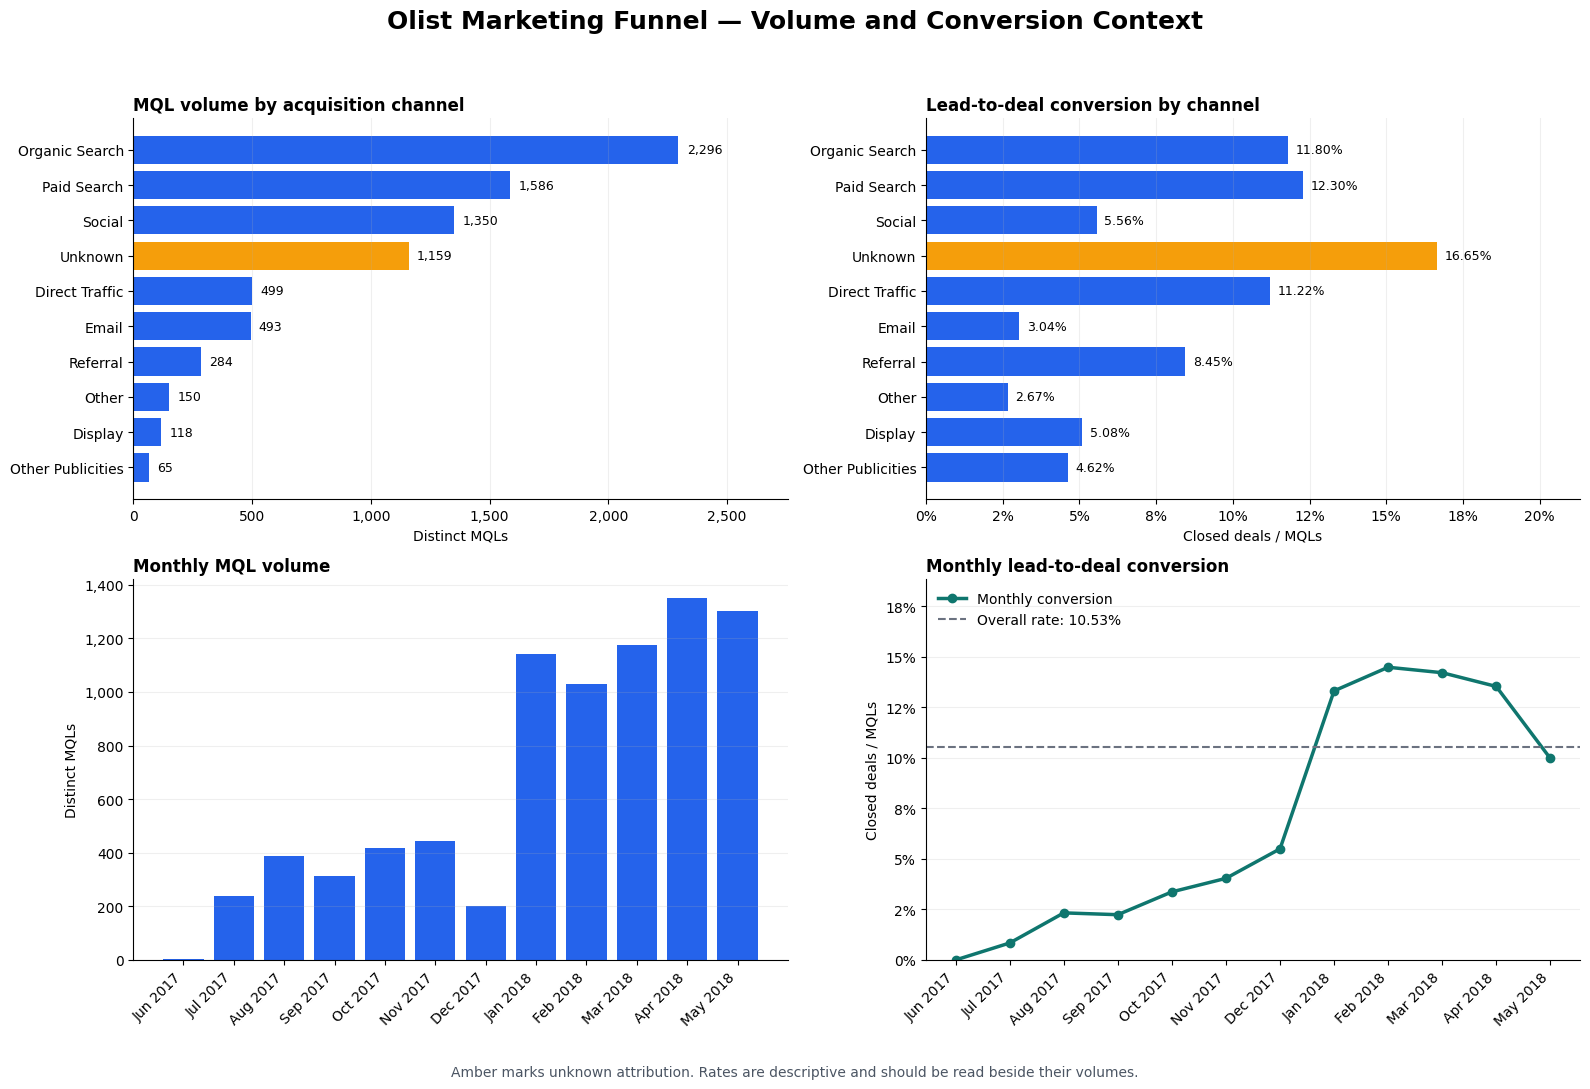

,check,result,observed
0,Channel chart includes every channel,True,10
1,Monthly chart includes every observed month,True,12
2,Charted channel MQLs reconcile,True,8000
3,Charted monthly closed deals reconcile,True,842
4,Unknown attribution remains visible,True,1


In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

# Reuse the verified Lesson 7 summaries; do not recalculate from raw joined rows.
channel_chart_data = channel_performance.sort_values("mqls", ascending=True).copy()
channel_chart_data["channel_label"] = (
    channel_chart_data["origin"]
    .str.replace("_", " ", regex=False)
    .str.title()
)
channel_chart_data["chart_color"] = channel_chart_data["origin"].map(
    lambda channel: "#F59E0B" if channel == "unknown" else "#2563EB"
)

monthly_chart_data = monthly_performance.copy()
monthly_chart_data["month_label"] = monthly_chart_data["contact_month"].dt.strftime("%b %Y")
overall_conversion_pct = closed_deal_count / mql_count * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.patch.set_facecolor("white")
fig.suptitle(
    "Olist Marketing Funnel — Volume and Conversion Context",
    fontsize=18,
    fontweight="bold",
    y=0.98,
)

# Panel 1: channel MQL volume.
channel_volume_axis = axes[0, 0]
volume_bars = channel_volume_axis.barh(
    channel_chart_data["channel_label"],
    channel_chart_data["mqls"],
    color=channel_chart_data["chart_color"],
)
channel_volume_axis.set_title("MQL volume by acquisition channel", loc="left", fontweight="bold")
channel_volume_axis.set_xlabel("Distinct MQLs")
channel_volume_axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
channel_volume_axis.set_xlim(0, channel_chart_data["mqls"].max() * 1.20)
for bar, value in zip(volume_bars, channel_chart_data["mqls"]):
    channel_volume_axis.text(
        value + 35,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=9,
    )

# Panel 2: channel lead-to-deal conversion, in the identical channel order.
channel_conversion_axis = axes[0, 1]
conversion_bars = channel_conversion_axis.barh(
    channel_chart_data["channel_label"],
    channel_chart_data["lead_to_deal_conversion_pct"],
    color=channel_chart_data["chart_color"],
)
channel_conversion_axis.set_title("Lead-to-deal conversion by channel", loc="left", fontweight="bold")
channel_conversion_axis.set_xlabel("Closed deals / MQLs")
channel_conversion_axis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
channel_conversion_axis.set_xlim(
    0,
    channel_chart_data["lead_to_deal_conversion_pct"].max() * 1.28,
)
for bar, value in zip(
    conversion_bars,
    channel_chart_data["lead_to_deal_conversion_pct"],
):
    channel_conversion_axis.text(
        value + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=9,
    )

# Panel 3: monthly MQL volume.
month_positions = range(len(monthly_chart_data))
monthly_volume_axis = axes[1, 0]
monthly_volume_axis.bar(
    month_positions,
    monthly_chart_data["mqls"],
    color="#2563EB",
)
monthly_volume_axis.set_title("Monthly MQL volume", loc="left", fontweight="bold")
monthly_volume_axis.set_ylabel("Distinct MQLs")
monthly_volume_axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
monthly_volume_axis.set_xticks(list(month_positions))
monthly_volume_axis.set_xticklabels(
    monthly_chart_data["month_label"],
    rotation=45,
    ha="right",
)

# Panel 4: monthly conversion with the portfolio-level benchmark.
monthly_conversion_axis = axes[1, 1]
monthly_conversion_axis.plot(
    list(month_positions),
    monthly_chart_data["lead_to_deal_conversion_pct"],
    color="#0F766E",
    marker="o",
    linewidth=2.5,
    label="Monthly conversion",
)
monthly_conversion_axis.axhline(
    overall_conversion_pct,
    color="#6B7280",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall rate: {overall_conversion_pct:.2f}%",
)
monthly_conversion_axis.set_title("Monthly lead-to-deal conversion", loc="left", fontweight="bold")
monthly_conversion_axis.set_ylabel("Closed deals / MQLs")
monthly_conversion_axis.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
monthly_conversion_axis.set_xticks(list(month_positions))
monthly_conversion_axis.set_xticklabels(
    monthly_chart_data["month_label"],
    rotation=45,
    ha="right",
)
monthly_conversion_axis.set_ylim(
    0,
    monthly_chart_data["lead_to_deal_conversion_pct"].max() * 1.30,
)
monthly_conversion_axis.legend(frameon=False, loc="upper left")

for axis in axes.flat:
    axis.grid(axis="x" if axis in axes[0] else "y", alpha=0.20)
    axis.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5,
    0.01,
    "Amber marks unknown attribution. Rates are descriptive and should be read beside their volumes.",
    ha="center",
    fontsize=10,
    color="#4B5563",
)
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

lesson_8_chart_checks = pd.DataFrame(
    [
        {
            "check": "Channel chart includes every channel",
            "result": len(channel_chart_data) == channel_performance["origin"].nunique(),
            "observed": len(channel_chart_data),
        },
        {
            "check": "Monthly chart includes every observed month",
            "result": len(monthly_chart_data) == monthly_performance["contact_month"].nunique(),
            "observed": len(monthly_chart_data),
        },
        {
            "check": "Charted channel MQLs reconcile",
            "result": int(channel_chart_data["mqls"].sum()) == mql_count,
            "observed": int(channel_chart_data["mqls"].sum()),
        },
        {
            "check": "Charted monthly closed deals reconcile",
            "result": int(monthly_chart_data["closed_deals"].sum()) == closed_deal_count,
            "observed": int(monthly_chart_data["closed_deals"].sum()),
        },
        {
            "check": "Unknown attribution remains visible",
            "result": bool(channel_chart_data["origin"].eq("unknown").any()),
            "observed": int(channel_chart_data["origin"].eq("unknown").sum()),
        },
    ]
)

display(lesson_8_chart_checks)


## Lesson 8 — Build honest dashboard charts in Python

We already trust the tables. Now we will turn them into visuals without changing the calculations.

### Chart design decisions

1. **Separate volume from rate.** MQL counts and conversion percentages use different units, so they belong in separate panels rather than on a confusing shared scale.
2. **Keep the same category order.** Channel volume and channel conversion will use the same vertical order so comparisons are easy.
3. **Expose data quality.** The `unknown` attribution category will remain visible and use an amber warning color instead of being silently removed.
4. **Add context.** The monthly conversion chart will include the overall 10.53% conversion rate as a reference line.

The four panels answer four questions: which channels supply volume, which channels convert, when lead volume changed, and when conversion changed.


## Lesson 8 result

The four-panel dashboard rendered successfully, and all five chart-quality checks passed.

- Channel coverage: 10 of 10 acquisition categories
- Monthly coverage: 12 of 12 observed months
- Channel MQL reconciliation: 8,000
- Monthly closed-deal reconciliation: 842
- Unknown attribution: retained and highlighted as a data-quality warning

### What the visuals make clear

- Organic search supplies the most lead volume.
- Paid search has the strongest conversion among named channels with at least 100 MQLs.
- Unknown attribution shows a high rate but is not an actionable channel.
- MQL volume rises sharply in 2018.
- February 2018 has the strongest qualified monthly conversion, while April 2018 has the highest lead volume.

**Lesson learned:** a dashboard is not decoration. Each chart must preserve the KPI denominator, show enough context to prevent misleading comparisons, and make data-quality limitations visible. Counts and rates stay in separate panels—no dual axes.